In [ ]:
data_file = open ("/content/drive/MyDrive/Fall 2026/Text Mining/mnist_train_100.csv",'r')
data_list = data_file.readlines ()
data_file.close()

In [ ]:
len(data_list)

100

In [ ]:
data_list[0]

'5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,18,18,18,126,136,175,26,166,255,247,127,0,0,0,0,0,0,0,0,0,0,0,0,30,36,94,154,170,253,253,253,253,253,225,172,253,242,195,64,0,0,0,0,0,0,0,0,0,0,0,49,238,253,253,253,253,253,253,253,253,251,93,82,82,56,39,0,0,0,0,0,0,0,0,0,0,0,0,18,219,253,253,253,253,253,198,182,247,241,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,80,156,107,253,253,205,11,0,43,154,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,14,1,154,253,90,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,139,253,190,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11,190,253,70,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,35,241,225,160,108,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,81,240,253,253,119,25,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,

In [ ]:
import numpy
import matplotlib.pyplot
%matplotlib inline

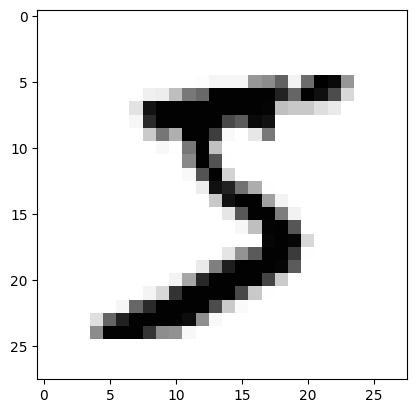

In [ ]:
all_values = data_list [0]. split (',')
image_array = numpy.asarray (all_values [1:], dtype=float). reshape ((28,28))
matplotlib.pyplot.imshow(image_array, cmap = 'Greys', interpolation ='None')

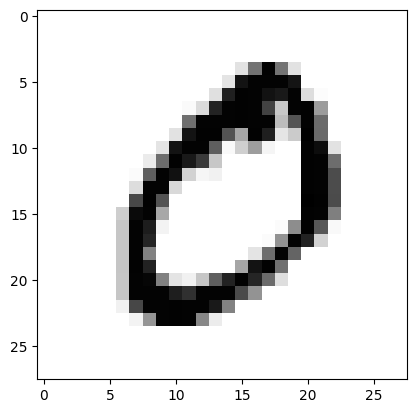

In [ ]:
all_values = data_list [1]. split (',')
image_array = numpy.asarray (all_values [1:], dtype=float). reshape ((28,28))
matplotlib.pyplot.imshow(image_array, cmap = 'Greys', interpolation ='None')

In [ ]:
import imageio.v3
import glob

In [ ]:
import numpy
import scipy.special
import matplotlib.pyplot

class neuralNetwork:
  def __init__(self, inputnodes, hiddennodes, outputnodes, learningrate):
# set number of nodes
      self.inodes = inputnodes
      self.hnodes = hiddennodes
      self.onodes = outputnodes
# link weight matrices, wih and who
      self.wih = numpy.random.normal (0.0,pow (self.inodes, -0.5), (self.hnodes, self.inodes))
      self.who = numpy.random.normal (0.0, pow (self.hnodes, -0.5), (self.onodes, self.hnodes))
      self.lr = learningrate
  #activation function is the sigmoid function
      self.activation_function = lambda x: scipy.special.expit (x)
      pass

#train neural network
  def train (self,inputs_list, targets_list):
#convery inputs to array
    inputs = numpy.array (inputs_list, ndmin=2).T
    targets = numpy.array (targets_list, ndmin=2).T

#calculate signals into hidden layers
    hidden_inputs = numpy.dot(self.wih, inputs)
#calculate the signals emerging from hidden layer
    hidden_outputs = self.activation_function (hidden_inputs)

#calculate signals into final output layer
    final_inputs=numpy.dot(self.who, hidden_outputs)
#calcualte signals emerging from final output layer
    final_outputs = self.activation_function(final_inputs)
# output layer error
    output_errors = targets - final_outputs
# hidden layer error is the output_errors, split by weights, recombined at hidden nodes
    hidden_errors = numpy.dot (self.who.T,output_errors)

# update the weights for the links between the hidden and output laters
    self.who += self.lr * numpy.dot ((output_errors * final_outputs * (1.0-final_outputs)),
                                     numpy.transpose (hidden_outputs))
#update the weights for the links between the input and hidden layers
    self.wih += self.lr * numpy.dot ((hidden_errors * hidden_outputs * (1.0-hidden_outputs)), numpy.transpose (inputs))
    pass

  def query (self, inputs_list):

    inputs = numpy.array (inputs_list, ndmin=2).T

# caculate signals into hidden layer
    hidden_inputs = numpy.dot(self.wih, inputs)
  #calculate signals emerging from hidden layer
    hidden_outputs = self.activation_function(hidden_inputs)

    final_inputs = numpy.dot (self.who, hidden_outputs)
    final_outputs= self.activation_function (final_inputs)


    return final_outputs

In [ ]:
input_nodes = 784
hidden_nodes = 200
output_nodes = 10

learning_rate = 0.015

n=neuralNetwork (input_nodes, hidden_nodes, output_nodes, learning_rate)


In [ ]:
n = neuralNetwork(input_nodes,hidden_nodes,output_nodes,learning_rate)

In [ ]:
training_data_file = open ("/content/drive/MyDrive/Fall 2026/Text Mining/mnist_train (3).csv",'r')
training_data_list = training_data_file.readlines ()
training_data_file.close()

In [ ]:
epochs = 10

for e in range(epochs):
    for record in training_data_list:
        all_values = record.split(',')
        inputs = (numpy.asarray(all_values[1:],dtype=float) / 255.0 * 0.99) + 0.01
        targets = numpy.zeros(output_nodes) + 0.01
        targets[int(all_values[0])] = 0.99
        n.train(inputs, targets)
        pass
    pass

In [ ]:
test_data_file = open ("/content/drive/MyDrive/Fall 2026/Text Mining/mnist_test.csv")
test_data_list = test_data_file.readlines ()
test_data_file.close ()

In [ ]:
scorecard = []

In [ ]:
for record in test_data_list:
  all_values=record.split (',')
  correct_label = int(all_values[0])
  inputs = (numpy.asarray(all_values[1:], dtype = float) / 255.0 * 0.99) + 0.1
  outputs = n.query (inputs)
  label = numpy.argmax(outputs)
  if (label == correct_label):
    scorecard.append(1)
  else:
    scorecard.append(0)
    pass
  pass

In [ ]:
print (scorecard)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [ ]:
scorecard_array = numpy.asarray(scorecard)
print ("performance = ", scorecard_array.sum() / scorecard_array.size)

performance =  0.9448


In [ ]:
import numpy
import scipy.special
import matplotlib.pyplot
from PIL import Image
import glob
class neuralNetwork:
  def __init__(self, inputnodes, hiddennodes, outputnodes, learningrate):

      self.inodes = inputnodes
      self.hnodes = hiddennodes
      self.onodes = outputnodes

      self.wih = numpy.random.normal (0.0,pow (self.inodes, -0.5), (self.hnodes, self.inodes))
      self.who = numpy.random.normal (0.0, pow (self.hnodes, -0.5), (self.onodes, self.hnodes))

      self.lr = learningrate

      self.activation_function = lambda x: scipy.special.expit (x)

      pass


  def train (self,inputs_list, targets_list):

    inputs = numpy.array (inputs_list, ndmin=2).T
    targets = numpy.array (targets_list, ndmin=2).T


    hidden_inputs = numpy.dot(self.wih, inputs)
    hidden_outputs = self.activation_function (hidden_inputs)


    final_inputs=numpy.dot(self.who, hidden_outputs)

    final_outputs = self.activation_function(final_inputs)

    output_errors = targets - final_outputs

    hidden_errors = numpy.dot (self.who.T,output_errors)


    self.who += self.lr * numpy.dot ((output_errors * final_outputs * (1.0-final_outputs)),
                                     numpy.transpose (hidden_outputs))

    self.wih += self.lr * numpy.dot ((hidden_errors * hidden_outputs * (1.0-hidden_outputs)), numpy.transpose (inputs))
    pass

  def query (self, inputs_list):

    inputs = numpy.array (inputs_list, ndmin=2).T


    hidden_inputs = numpy.dot(self.wih, inputs)
    hidden_outputs = self.activation_function(hidden_inputs)

    final_inputs = numpy.dot (self.who, hidden_outputs)
    final_outputs= self.activation_function (final_inputs)


    return final_outputs

In [ ]:
input_nodes = 784
hidden_noes = 200
output_nodes = 10

learning_rate = 0.01

n = neuralNetwork(input_nodes,hidden_nodes,output_nodes, learning_rate)

In [ ]:
epochs = 10

for e in range (epochs):
  for record in training_data_list:
    all_values = record.split (',')
    inputs = (numpy.asarray(all_values [1:], dtype=float) / 255.0 * 0.99)+0.01
    targets = numpy.zeros (output_nodes) + 0.01
    targets[int(all_values [0])] = 0.99
    n.train (inputs, targets)
    pass
  pass

In [ ]:
training_data_file = open ("/content/drive/MyDrive/Fall 2026/Text Mining/mnist_train (3).csv",'r')
training_data_list = training_data_file.readlines ()
training_data_file.close()

In [ ]:
import numpy
import scipy.special
import matplotlib.pyplot
from PIL import Image
import glob

# our own image test data set
our_own_dataset = []

# load the png image data as test data set
for image_file_name in glob.glob('/content/drive/MyDrive/Fall 2026/Text Mining/?.png'):

    # use the filename to set the correct label
    label = int(image_file_name[-5:-4])

    # load image data from png files into an array using PIL for resizing
    print ("loading ... ", image_file_name)

    # Open the image, convert to grayscale, and resize to 28x28
    img = Image.open(image_file_name).convert('L')
    img_resized = img.resize((28, 28))
    img_array = numpy.asarray(img_resized)

    # reshape from 28x28 to list of 784 values, invert values
    img_data  = 255.0 - img_array.reshape(784)

    # then scale data to range from 0.01 to 1.0
    img_data = (img_data / 255.0 * 0.99) + 0.01
    print(numpy.min(img_data))
    print(numpy.max(img_data))

    # append label and image data  to test data set
    record = numpy.append(label,img_data)
    our_own_dataset.append(record)

    pass

loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/1.png
0.01
0.9844705882352941
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/2.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/3.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/4.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/5.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/6.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/7.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/8.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/9.png
0.01
1.0
loading ...  /content/drive/MyDrive/Fall 2026/Text Mining/0.png
0.01
1.0


[[9.86718528e-05]
 [9.69952473e-01]
 [2.74369792e-02]
 [2.73519825e-02]
 [1.89068771e-03]
 [1.12882724e-02]
 [9.85535456e-03]
 [1.11025867e-02]
 [2.08755776e-02]
 [1.77813451e-02]]
network says  1
match!


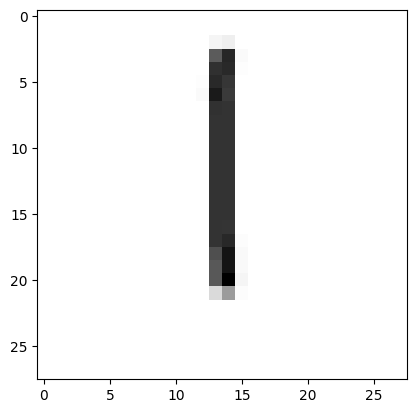

In [ ]:
# record to test
item = 0

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[0.00853999]
 [0.00021099]
 [0.14720406]
 [0.00037271]
 [0.01014668]
 [0.18950551]
 [0.04992832]
 [0.10137922]
 [0.02846196]
 [0.0069609 ]]
network says  5
no match!


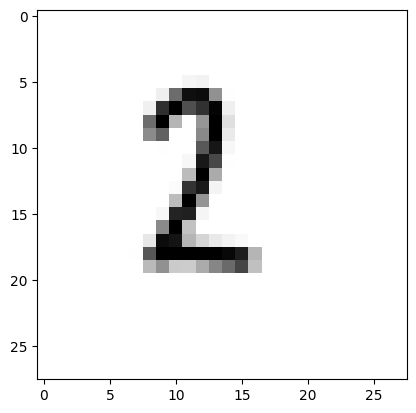

In [ ]:
# record to test
item = 1

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[4.10808597e-03]
 [7.06727971e-03]
 [8.47364247e-01]
 [1.52092703e-03]
 [1.99357476e-02]
 [2.50963628e-03]
 [5.18780509e-04]
 [3.05714178e-01]
 [3.12093297e-03]
 [4.97393269e-01]]
network says  2
no match!


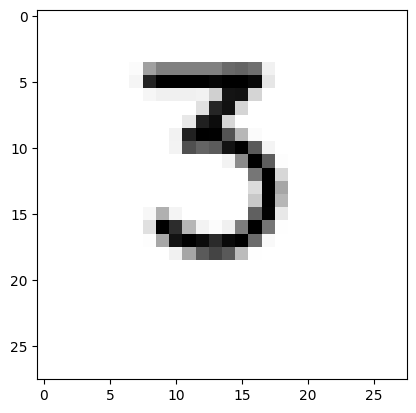

In [ ]:
# record to test
item = 2

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[1.91476181e-04]
 [4.54492055e-01]
 [3.74923049e-04]
 [4.58698386e-02]
 [1.28699068e-02]
 [4.91923735e-02]
 [1.05086722e-04]
 [2.49657383e-02]
 [3.38583375e-02]
 [8.04901477e-01]]
network says  9
no match!


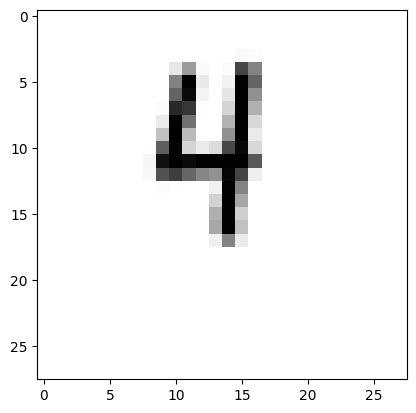

In [ ]:
# record to test
item = 3

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[3.35198525e-03]
 [1.09869827e-03]
 [8.87536294e-03]
 [3.20447791e-04]
 [4.01711044e-02]
 [2.42675620e-02]
 [3.94689443e-02]
 [5.21895609e-02]
 [1.77578559e-01]
 [5.80078999e-01]]
network says  9
no match!


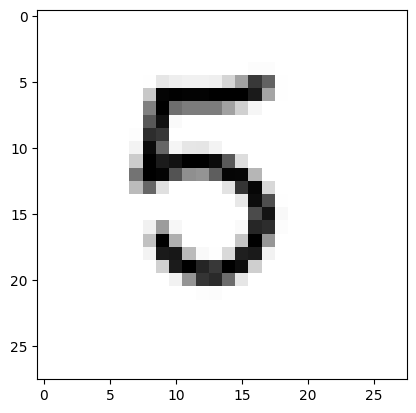

In [ ]:
# record to test
item = 4

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[0.00139682]
 [0.01354369]
 [0.00763864]
 [0.00568282]
 [0.02246954]
 [0.05463641]
 [0.96351812]
 [0.00493943]
 [0.01491642]
 [0.01298485]]
network says  6
match!


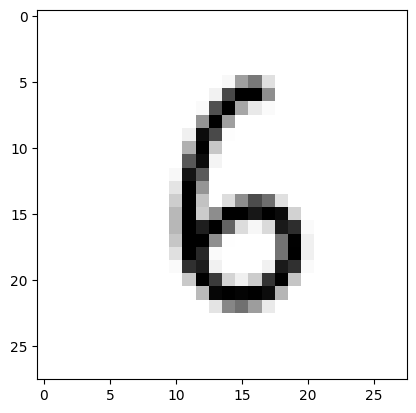

In [ ]:
# record to test
item = 5

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[3.13976535e-03]
 [1.05634144e-03]
 [5.02161158e-02]
 [1.26632452e-01]
 [1.25315888e-02]
 [5.89706473e-03]
 [1.10556799e-04]
 [7.16453367e-01]
 [1.20519020e-03]
 [5.63722594e-01]]
network says  7
match!


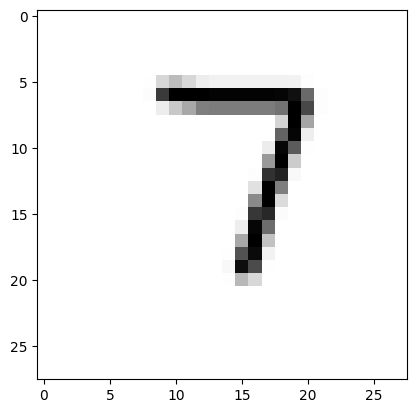

In [ ]:
# record to test
item = 6

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[0.00234383]
 [0.01615534]
 [0.00619723]
 [0.01665106]
 [0.10262594]
 [0.00332513]
 [0.00260137]
 [0.01409265]
 [0.56023914]
 [0.34964022]]
network says  8
match!


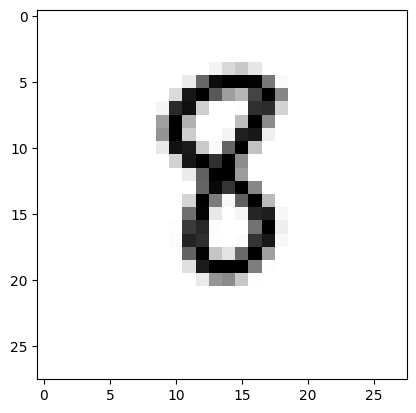

In [ ]:
# record to test
item = 7

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[4.74934360e-03]
 [6.04008178e-03]
 [1.23091074e-03]
 [6.30633414e-02]
 [3.24711853e-01]
 [2.71598187e-03]
 [5.51297803e-04]
 [3.46278046e-02]
 [1.45598953e-02]
 [9.18525340e-01]]
network says  9
match!


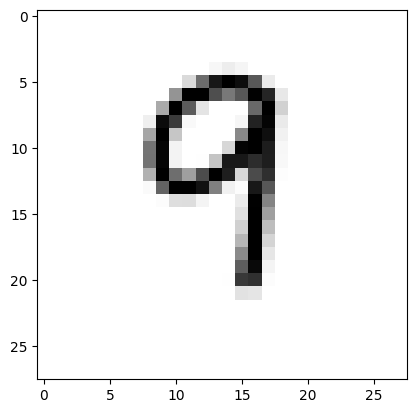

In [ ]:
# record to test
item = 8

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass

[[8.23023164e-01]
 [8.01032076e-04]
 [3.98487510e-02]
 [7.09075314e-03]
 [1.08126636e-02]
 [3.93877457e-03]
 [6.88147680e-03]
 [2.91190026e-02]
 [8.55320828e-03]
 [2.29314091e-01]]
network says  0
match!


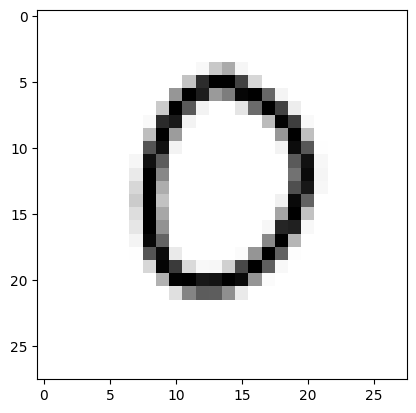

In [ ]:
# record to test
item = 9

# plot image
matplotlib.pyplot.imshow(our_own_dataset[item][1:].reshape(28,28), cmap='Greys', interpolation='None')

# correct answer is first value
correct_label = our_own_dataset[item][0]
# data is remaining values
inputs = our_own_dataset[item][1:]

# query the network
outputs = n.query(inputs)
print (outputs)

# the index of the highest value corresponds to the label
label = numpy.argmax(outputs)
print("network says ", label)
# append correct or incorrect to list
if (label == correct_label):
    print ("match!")
else:
    print ("no match!")
    pass